# PC01 — Xác định phạm vi khách hàng và xây dựng RFM

> **Cách đọc:** Kết quả và nhận xét chính hiển thị trực tiếp. Nhấn **Xem chi tiết** để mở bảng đối chiếu; nhật ký tiến trình cũng được thu gọn. Các phép tính và dữ liệu vẫn được giữ đầy đủ.

## Mục tiêu nghiệp vụ
Doanh nghiệp muốn nhận diện những kiểu khách khác nhau để ưu tiên nghiên cứu chăm sóc và duy trì mua hàng. Trước khi chia nhóm, cần thống nhất **đang nói về khách nào, đơn nào và giá trị nào**. Nếu một nơi đếm mọi đơn còn nơi khác cộng tiền delivered, nhóm thu được sẽ khó giải thích dù thuật toán vẫn chạy.

Notebook này tiếp nhận dữ liệu đã qua tiền xử lý chung của nhóm, xác minh phạm vi và tính lại RFM. Kết quả bàn giao là một dòng mỗi mã khách đủ điều kiện, có nguồn và tổng tiền đối soát được. **Chưa huấn luyện mô hình ở PC01.**

## Câu hỏi cần trả lời
1. Trạng thái trong dữ liệu là lịch sử sự kiện hay nhãn tại bản ghi nguồn?
2. Những khách nào đủ điều kiện, những khách nào cần giữ riêng?
3. R, F và M được tính qua những cấp dữ liệu nào?
4. Việc JOIN, lọc và tổng hợp có làm mất khách, mất đơn hoặc nhân tiền không?

## Quy ước và cách đọc
Mốc phân tích là **31/12/2022**, không phải ngày hiện tại. Đơn tính RFM mang trạng thái nguồn `delivered`. Đây là quy ước mô tả theo dữ liệu, chưa chứng nhận giao dịch đã quyết toán. Ngày đặt dùng cho Recency, không thay bằng ngày giao khi ngữ nghĩa chưa xác minh.

Mỗi mục đi theo **câu hỏi → định nghĩa/công thức → tính toán → bảng/hình → nhận xét → giới hạn**. Các nhận xét về kết quả dự án được sinh từ biến tính toán, không nhập số minh họa làm kết quả.


## Cách đọc thuật ngữ và kết quả

- **Recency:** số ngày từ đơn delivered gần nhất đến 31/12/2022.
- **Frequency:** số đơn delivered đủ điều kiện của một khách.
- **Monetary:** tổng tiền sau giảm giá của các đơn đó, chưa là lợi nhuận hoặc thực thu.
- **Cụm:** nhóm khách do thuật toán tạo; mã nhóm chỉ để nhận diện.
- **Mẫu số:** tổng khách hoặc tổng đơn dùng để tính tỷ lệ; luôn đọc đúng phạm vi cạnh bảng.

Các ký hiệu và công thức cần thiết được giải thích ngay tại mục sử dụng.


## Chuẩn bị môi trường và nguồn dữ liệu

Notebook tự tìm thư mục dự án và nạp notebook hỗ trợ 00. RFM được tính từ raw/common và đối soát trực tiếp với dòng hàng nguồn; không đọc kết quả phân cụm cũ hay JSON mô hình. PC01–PC02 chưa huấn luyện. PC03 thử và chọn mô hình mới; PC04–PC06 tự huấn luyện lại khi chạy ở kernel riêng. Trong cùng kernel, các phép tính được dùng lại từ bộ nhớ.

Mặc định lượt là combined_v1. Nếu CSV của lượt đó đã tồn tại và khác kết quả mới, chương trình dừng lưu; chọn tên DATATHON_MODEL_RUN mới hoặc chủ động sao lưu/xóa CSV cũ. Kết quả cũ không quyết định lựa chọn mô hình.


In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

# Nạp định nghĩa hỗ trợ riêng, không sửa file Python dùng chung của nhóm.
_support_path = ROOT / 'notebook/05_phan_khuc_khach_hang/00_ham_ho_tro_phan_cum.ipynb'
_support_doc = json.loads(_support_path.read_text(encoding='utf-8'))
for _cell_index, _cell in enumerate(_support_doc['cells']):
    if _cell['cell_type'] == 'code':
        exec(compile(''.join(_cell['source']), f'{_support_path}:cell{_cell_index+1}', 'exec'), globals())

from ham_dung_chung import segmentation_study
sys.dont_write_bytecode = True
Study = phan_cum_tich_hop().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "combined_v1")
study = Study(ROOT, "PC01")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC01 | Lượt mô hình: combined_v1


### PC01.0 — Kiểm chứng đầu vào trước phân cụm

Sử dụng hai bảng common đã được GD2 kiểm chứng. Kiểm tra mã đơn, mã khách, trạng thái, ngày và tiền của từng đơn; sau đó tính lại RFM độc lập từ các đơn nguồn đã chọn. Chỉ khi tất cả đối chiếu đạt mới chuyển sang phân tích.

Tiền được cộng bằng Decimal để giữ độ chính xác thập phân. Không trình bày lại công thức tiền dòng hàng ở đây vì đã thuộc bước tiền xử lý. Bảng dưới cho biết kết quả kiểm chứng thực tế.


In [2]:
independent_audit = phan_cum_tich_hop().independent_audit
study.table('independent_source_audit','Đối soát tiền raw → common → RFM từng khách', independent_audit(ROOT));


,Số đơn,eligible_orders,Số khách,exact_net_total,all_order_net_exact_match_raw,reference,method
0,646945,516716,85115,12518175957.20,True,independent raw/common reconciliation,Exact Decimal sum of all raw items; one-to-one...


## PC01.1 — Nguồn dữ liệu, cấp quan sát và hợp đồng sử dụng

Một khách có thể có nhiều đơn; mỗi đơn có thể gồm nhiều sản phẩm. Bảng orders_common giữ một dòng cho mỗi đơn, còn order_items_common giữ từng dòng hàng. Bảng đưa vào phân cụm phải có một dòng cho mỗi khách.

Ví dụ, nếu tiền của một đơn được ghép vào ba dòng sản phẩm rồi cộng lại, tiền đơn có thể bị tính ba lần. Vì vậy, tính RFM từ bảng đơn; chỉ ghép dòng hàng khi phân tích sản phẩm và kiểm tra quan hệ ghép.

Kiểm mã nguồn để xác nhận đúng phiên bản file, kiểm mã đơn không trùng và dùng Decimal khi đọc tiền. Đây là kiểm tra tính nhất quán dữ liệu, chưa chứng minh đã thu tiền hoặc xác nhận được người thực đứng sau mỗi mã khách.


In [3]:
orders=study.orders()
source_schema=pd.DataFrame({'Cột':orders.columns,'Kiểu đọc':[str(t) for t in orders.dtypes]})
study.table('source_schema','Kiểu dữ liệu đầu vào common',source_schema)
require(orders.order_id.is_unique,'Đơn phải duy nhất')
study.note(f'Đọc {len(orders):,} đơn common. Tiền net_amount giữ Decimal; không suy float hoặc dùng payment để thay trạng thái.')

,Cột,Kiểu đọc
0,order_id,object
1,customer_id,object
2,order_status,object
3,order_date,datetime64[ns]
4,net_amount,object
5,order_before_signup_flag,object
6,delivered_missing_shipment_flag,object


Đọc 646,945 đơn common. Tiền net_amount giữ Decimal; không suy float hoặc dùng payment để thay trạng thái.

## PC01.2 — Trạng thái đơn và bằng chứng từ bảng liên quan

Bảng orders chỉ có một trạng thái trên mỗi đơn và không lưu lịch sử cập nhật. Ta biết nhãn đang ghi trong dữ liệu, chưa biết đơn đã đi qua những trạng thái nào hoặc nhãn được cập nhật khi nào.

Bảng độ phủ đếm, với mỗi trạng thái, có bao nhiêu đơn tìm thấy bản ghi trong payments, shipments, returns hoặc reviews. Một đơn có ba bản ghi hoàn trả vẫn chỉ tính một lần khi hỏi “đơn này có chi tiết hoàn trả không”.

Số đơn theo các trạng thái có thể cộng thành tổng đơn vì mỗi đơn chỉ mang một nhãn. Số khách theo trạng thái không được cộng như vậy: cùng một khách có thể có cả đơn hủy và đơn delivered.

Giữ nguyên trạng thái nguồn. Payment dương chưa chứng nhận thực thu; shipped có ngày giao chưa chứng nhận đã giao; delivered thiếu shipment chưa đủ để kết luận nhãn sai. Ảnh hưởng của các cách hiểu khác được kiểm tra riêng ở PC05.


,Trạng thái,Số đơn,Có payments,Có shipments,Có returns,Có reviews
0,cancelled,59462,59462,0,0,0
1,created,7275,7275,0,0,0
2,delivered,516716,516716,516192,0,111369
3,paid,13577,13577,0,0,0
4,returned,36142,36142,36113,36062,0
5,shipped,13773,13773,13762,0,0


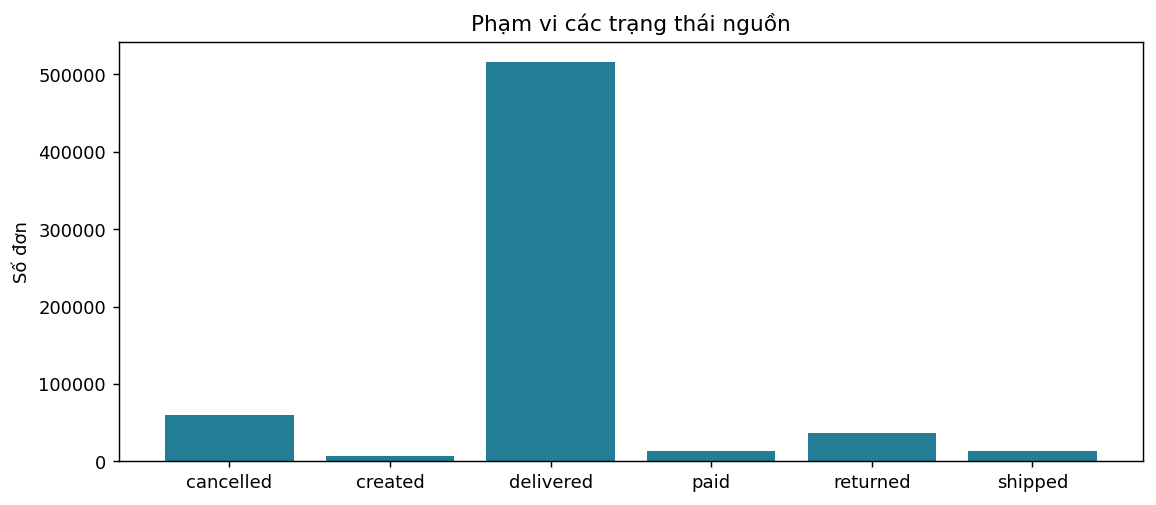

Có payment chỉ là có bản ghi; created/cancelled cũng có payment. Không đổi status từ bảng con. Returned thiếu returns và delivered thiếu shipment phải giữ cờ.

In [4]:
raw=ROOT/'data/raw'
children={name:set(pd.read_csv(raw/(name+'.csv'),dtype=str,usecols=['order_id']).order_id) for name in ['payments','shipments','returns','reviews']}
rows=[]
for status,g in orders.groupby('order_status'):
 row={'Trạng thái':status,'Số đơn':len(g)}
 for name,ids in children.items():row['Có '+name]=int(g.order_id.isin(ids).sum())
 rows.append(row)
coverage=study.table('status_coverage','Độ phủ trạng thái và bảng con',pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(9,4));ax.bar(coverage['Trạng thái'],coverage['Số đơn'],color='#237d95');ax.set(ylabel='Số đơn',title='Phạm vi các trạng thái nguồn');study.fig('status_counts','Số đơn theo trạng thái',fig)
study.note('Có payment chỉ là có bản ghi; created/cancelled cũng có payment. Không đổi status từ bảng con. Returned thiếu returns và delivered thiếu shipment phải giữ cờ.')

## PC01.3 — Tập khách phân tích và những khách ngoài phạm vi

Chỉ phân cụm khách có ít nhất một đơn delivered đủ điều kiện đến 31/12/2022. Toàn bộ danh sách khách được chia thành ba nhóm không trùng nhau: có đơn đủ điều kiện; không có bản ghi đơn; có đơn nhưng không có đơn đủ điều kiện. Cộng ba nhóm phải bằng tổng số khách nguồn.

Khách không có đơn delivered không có ngày mua tương ứng để tính Recency. Không gán Recency bằng 0 vì sẽ giống khách vừa mua, cũng không tự gán một số rất lớn để ép họ thành khách lâu chưa mua. Giữ riêng mã và lý do ngoài phạm vi.

Tỷ trọng khách đủ điều kiện tính trên toàn bộ danh sách khách. Các tỷ trọng cụm ở bước sau chỉ tính trên khách thực sự được phân cụm; không suy rộng chúng thành tỷ trọng của toàn bộ khách nguồn.


,Lý do,Số khách,Tỷ trọng
0,eligible_delivered,85115,0.698064
1,no_order_records,31684,0.259854
2,orders_but_no_eligible_delivered,5131,0.042082


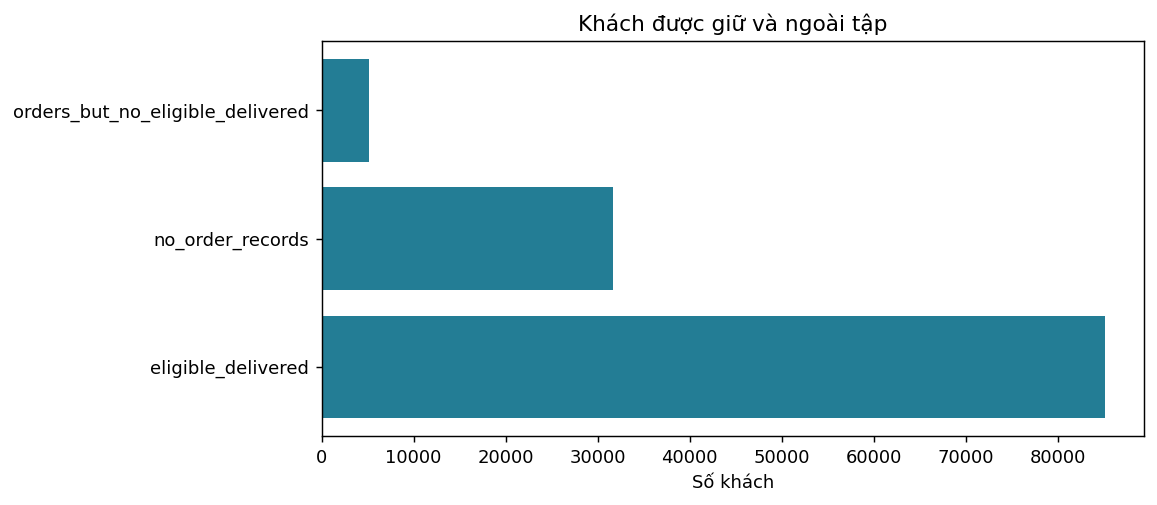

85,115/121,930 khách được phân cụm (69.81%); không suy rộng tỷ trọng cụm sang toàn bộ khách.

In [5]:
scope=study.scope.scope_reason.value_counts().rename_axis('Lý do').reset_index(name='Số khách')
scope['Tỷ trọng']=scope['Số khách']/scope['Số khách'].sum()
study.table('customer_scope','Phạm vi toàn bộ khách',scope)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(scope['Lý do'],scope['Số khách'],color='#237d95');ax.set(xlabel='Số khách',title='Khách được giữ và ngoài tập');study.fig('customer_scope','Phạm vi khách',fig)
require(scope['Số khách'].sum()==121930,'Mất khách trong bảng phạm vi')
study.note(f'{len(study.f):,}/{len(study.scope):,} khách được phân cụm ({len(study.f)/len(study.scope):.2%}); không suy rộng tỷ trọng cụm sang toàn bộ khách.')

## PC01.4 — Ba công thức RFM dùng trong phân cụm

Mỗi khách có ba đặc trưng trên cùng tập đơn delivered đủ điều kiện:

$$R_c=T-\max_{o\in D_c}t_o$$
$$F_c=|D_c|$$
$$M_c=\sum_{o\in D_c}Net_o$$

| Ký hiệu | Ý nghĩa ngay trong ba công thức này |
|---|---|
| c | Một khách hàng đang xét |
| T | Ngày tham chiếu 31/12/2022 |
| D_c | Các đơn delivered của khách đó, có ngày đặt không sau ngày tham chiếu |
| o | Một đơn thuộc tập đơn được chọn |
| t_o | Ngày đặt của đơn đó |
| Net_o | Giá trị đơn sau giảm giá đã được GD2 kiểm chứng |
| R_c | Số ngày từ lần đặt đơn đủ điều kiện gần nhất đến ngày tham chiếu |
| F_c | Số đơn riêng biệt đủ điều kiện |
| M_c | Tổng Net của các đơn đủ điều kiện |

Đơn cancelled không được cộng vào các chỉ tiêu RFM chính.

Monetary không phải lợi nhuận, tiền thực nhận hay giá trị khách hàng tương lai. Không cộng payment thêm vào Net. Sau tổng hợp, kiểm cả tổng đơn, tổng tiền và số liệu từng khách; chỉ khớp tổng chưa đủ phát hiện sai lệch bù trừ giữa khách.


In [6]:
selected=orders.loc[orders.order_status.eq('delivered') & orders.order_date.le(CUTOFF)].copy()
recomputed=rfm(selected)
a=study.f.set_index('customer_id').sort_index();b=recomputed.set_index('customer_id').sort_index()
require(a.index.equals(b.index),'Tập khách thay đổi')
require(a.Monetary.eq(b.Monetary).all() and a.Frequency.eq(b.Frequency).all() and a.Recency.eq(b.Recency).all(),'RFM không khớp')
study.table('rfm_preview','Ví dụ RFM thực tế',recomputed[['customer_id','last_order_date','Recency','Frequency','Monetary']].head(10))
checks=pd.DataFrame({'Kiểm tra':['Đơn duy nhất','Khách duy nhất','Tổng F bằng số đơn','Tổng M khớp Decimal','Khớp RFM baseline'], 'Đạt':[selected.order_id.is_unique,recomputed.customer_id.is_unique,recomputed.Frequency.sum()==len(selected),sum(recomputed.Monetary,Decimal(0))==sum(selected.net_amount,Decimal(0)),True]})
study.table('rfm_reconciliation','Đối soát độc lập RFM từ common',checks)
study.note(f'Tổng Net={sum(recomputed.Monetary,Decimal(0)):,} ĐVT nguồn, trên {len(selected):,} đơn; đối chiếu từng khách khớp baseline. Không dùng tên tiền tệ chưa xác minh.')

,Mã khách,last_order_date,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn)
0,1,2020-02-24,1041,4,98782.44
1,10,2022-05-06,239,10,256542.98
2,10000,2017-11-28,1859,1,37244.0
3,100001,2018-04-15,1721,2,41916.38
4,100009,2020-04-10,995,3,135092.40
5,100010,2022-12-20,11,6,49678.38
6,100011,2017-11-16,1871,2,62296.42
7,100012,2022-12-24,7,4,106697.03
8,100015,2020-07-26,888,1,29079.82
9,100017,2020-07-27,887,1,25660.92


,Kiểm tra,Đạt
0,Đơn duy nhất,True
1,Khách duy nhất,True
2,Tổng F bằng số đơn,True
3,Tổng M khớp Decimal,True
4,Khớp RFM baseline,True


Tổng Net=12,518,175,957.20 ĐVT nguồn, trên 516,716 đơn; đối chiếu từng khách khớp baseline. Không dùng tên tiền tệ chưa xác minh.

## PC01.5 — Cờ bất thường và chính sách giữ dữ liệu

Đơn đặt trước ngày đăng ký hoặc delivered thiếu shipment cần được ghi nhận, nhưng dữ liệu chưa đủ để kết luận nguyên nhân. Giữ các trường hợp theo chính sách tiền xử lý và thống kê số đơn chịu ảnh hưởng.

Muốn đọc tỷ lệ một cờ, lấy số đơn mang cờ chia số đơn delivered đang xét. Nếu chưa biết giá trị cờ, báo riêng phần chưa biết, không chuyển thành “không có cờ”. Một đơn có thể mang nhiều cờ nên không cộng các cờ thành tổng số lỗi duy nhất.

Không thay phạm vi chỉ để làm kết quả cụm đẹp hơn. PC05 sẽ thử riêng việc bỏ delivered thiếu shipment. Số đơn mang cờ và số khách có đơn mang cờ là hai chỉ tiêu khác nhau.


In [7]:
flags=[]
for col in ['order_before_signup_flag','delivered_missing_shipment_flag']:
 counts=selected[col].value_counts(dropna=False)
 for val,n in counts.items():flags.append({'Cờ':col,'Giá trị nguồn':str(val),'Số đơn delivered':int(n)})
study.table('retained_flags','Các cờ được giữ trong tập RFM',pd.DataFrame(flags))
study.note('Không dùng signup để sửa tuổi khách hoặc loại đơn. Đơn delivered thiếu shipment vẫn tham gia baseline; PC05 kiểm độ nhạy riêng. Hai cờ có thể chồng lấn, không cộng thành tổng lỗi.')

,Cờ,Giá trị nguồn,Số đơn delivered
0,order_before_signup_flag,True,382623
1,order_before_signup_flag,False,134093
2,delivered_missing_shipment_flag,False,516192
3,delivered_missing_shipment_flag,True,524


Không dùng signup để sửa tuổi khách hoặc loại đơn. Đơn delivered thiếu shipment vẫn tham gia baseline; PC05 kiểm độ nhạy riêng. Hai cờ có thể chồng lấn, không cộng thành tổng lỗi.

## PC01.6 — Thời gian, ý nghĩa phạm vi và điều kiện bàn giao

Ngày đặt đơn dùng để tính Recency. Ngày giao, ngày đổi trạng thái và ngày trích xuất dữ liệu là những thời điểm khác. Bộ dữ liệu chưa có đủ lịch sử để xác nhận trạng thái đã được biết tại từng ngày trong quá khứ.

Vì vậy, 31/12/2022 là mốc tính toán đã chọn, không phải bằng chứng mọi thông tin đều sẵn có đúng ngày đó. Kết quả dùng để mô tả dữ liệu, chưa dùng để chứng minh mô hình đã nhận diện đúng khách tại một mốc lịch sử.

Chuyển sang PC02 khi đã rõ tập khách và đơn, không trùng mã ở cấp cần thiết, RFM không thiếu và số đơn/tiền đã đối soát. Tiền thực thu, nghĩa của ngày giao và nguyên nhân bất thường vẫn cần xác minh nghiệp vụ.


In [8]:
definitions=pd.DataFrame([
{'Khái niệm':'order_date','Cách dùng':'Ngày đặt ghi nhận; dùng tính R','Không được suy':'Ngày giao hoặc ngày chuyển status'},
{'Khái niệm':'delivery_date','Cách dùng':'Bằng chứng bổ trợ, giả định độ nhạy','Không được suy':'Tự xác nhận shipped đã giao'},
{'Khái niệm':'31/12/2022','Cách dùng':'Mốc tham chiếu phân tích','Không được suy':'Ngày trích xuất/status sẵn có'},
{'Khái niệm':'delivered','Cách dùng':'Nhãn phạm vi theo nguồn','Không được suy':'Quyết toán xong, không bao giờ trả'}])
study.table('time_semantics','Quy ước và giới hạn thời gian',definitions)
study.note('Bàn giao PC02: cùng 85.115 khách, R/F/M liên tục, ngoài tập giữ riêng. Nếu thay định nghĩa phải ghi lại và tính lại, không sửa nhãn để hợp kết luận.')

,Khái niệm,Cách dùng,Không được suy
0,order_date,Ngày đặt ghi nhận; dùng tính R,Ngày giao hoặc ngày chuyển status
1,delivery_date,"Bằng chứng bổ trợ, giả định độ nhạy",Tự xác nhận shipped đã giao
2,31/12/2022,Mốc tham chiếu phân tích,Ngày trích xuất/status sẵn có
3,delivered,Nhãn phạm vi theo nguồn,"Quyết toán xong, không bao giờ trả"


Bàn giao PC02: cùng 85.115 khách, R/F/M liên tục, ngoài tập giữ riêng. Nếu thay định nghĩa phải ghi lại và tính lại, không sửa nhãn để hợp kết luận.

In [9]:
study.note("### Kết luận nghiệp vụ PC01 và điều kiện chuyển bước")
study.note(f'Tập RFM gồm {len(study.f):,} mã khách đủ điều kiện trong {len(study.scope):,} mã nguồn. Việc bỏ khách ngoài phạm vi khỏi mô hình là do không có RFM delivered có ý nghĩa, không phải đánh giá họ không có giá trị. RFM được tính lại và so từng khách; bước tiếp theo nghiên cứu phân bố và cách đo khoảng cách, chưa vội chọn thuật toán.')

### Kết luận nghiệp vụ PC01 và điều kiện chuyển bước

Tập RFM gồm 85,115 mã khách đủ điều kiện trong 121,930 mã nguồn. Việc bỏ khách ngoài phạm vi khỏi mô hình là do không có RFM delivered có ý nghĩa, không phải đánh giá họ không có giá trị. RFM được tính lại và so từng khách; bước tiếp theo nghiên cứu phân bố và cách đo khoảng cách, chưa vội chọn thuật toán.

In [10]:
part_manifest=study.finish()

Hoàn thành: {'part': 'PC01', 'state': 'completed', 'model_run': 'combined_v1', 'tables': 8, 'figures': 2}


## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).
